In [20]:
import sys
import os
from typing import NamedTuple
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), '../src'))
from utils_robot import read_utils
from utils_robot import generate_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom
from models import hgm

In [21]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [22]:
file_id = 19

weights = (0.1, -0.25, 1.)

neuron_labels = [f'N{i}' for i in range(20)]
# bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']
bhl_selection = ['REV', 'VENTRAL_TURN']

dims = 2

In [23]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename_gcamp,
 discrete_states, eigenworms) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]

# preprocess
pass

In [24]:
# generate
(filename,
 modes,
 traces_reconstructed,
 traces_residual,
 traces,
 params,
 params_manifold) = generate_utils.artificialize(weights, 'hgm',
												 filename_gcamp,
												 neuron_labels,
												 eigenworms,
												 discrete_states[bhl_selection],
												 n_dimensions=len(bhl_selection))

In [25]:
neuron_labels = neuron_labels[:5]

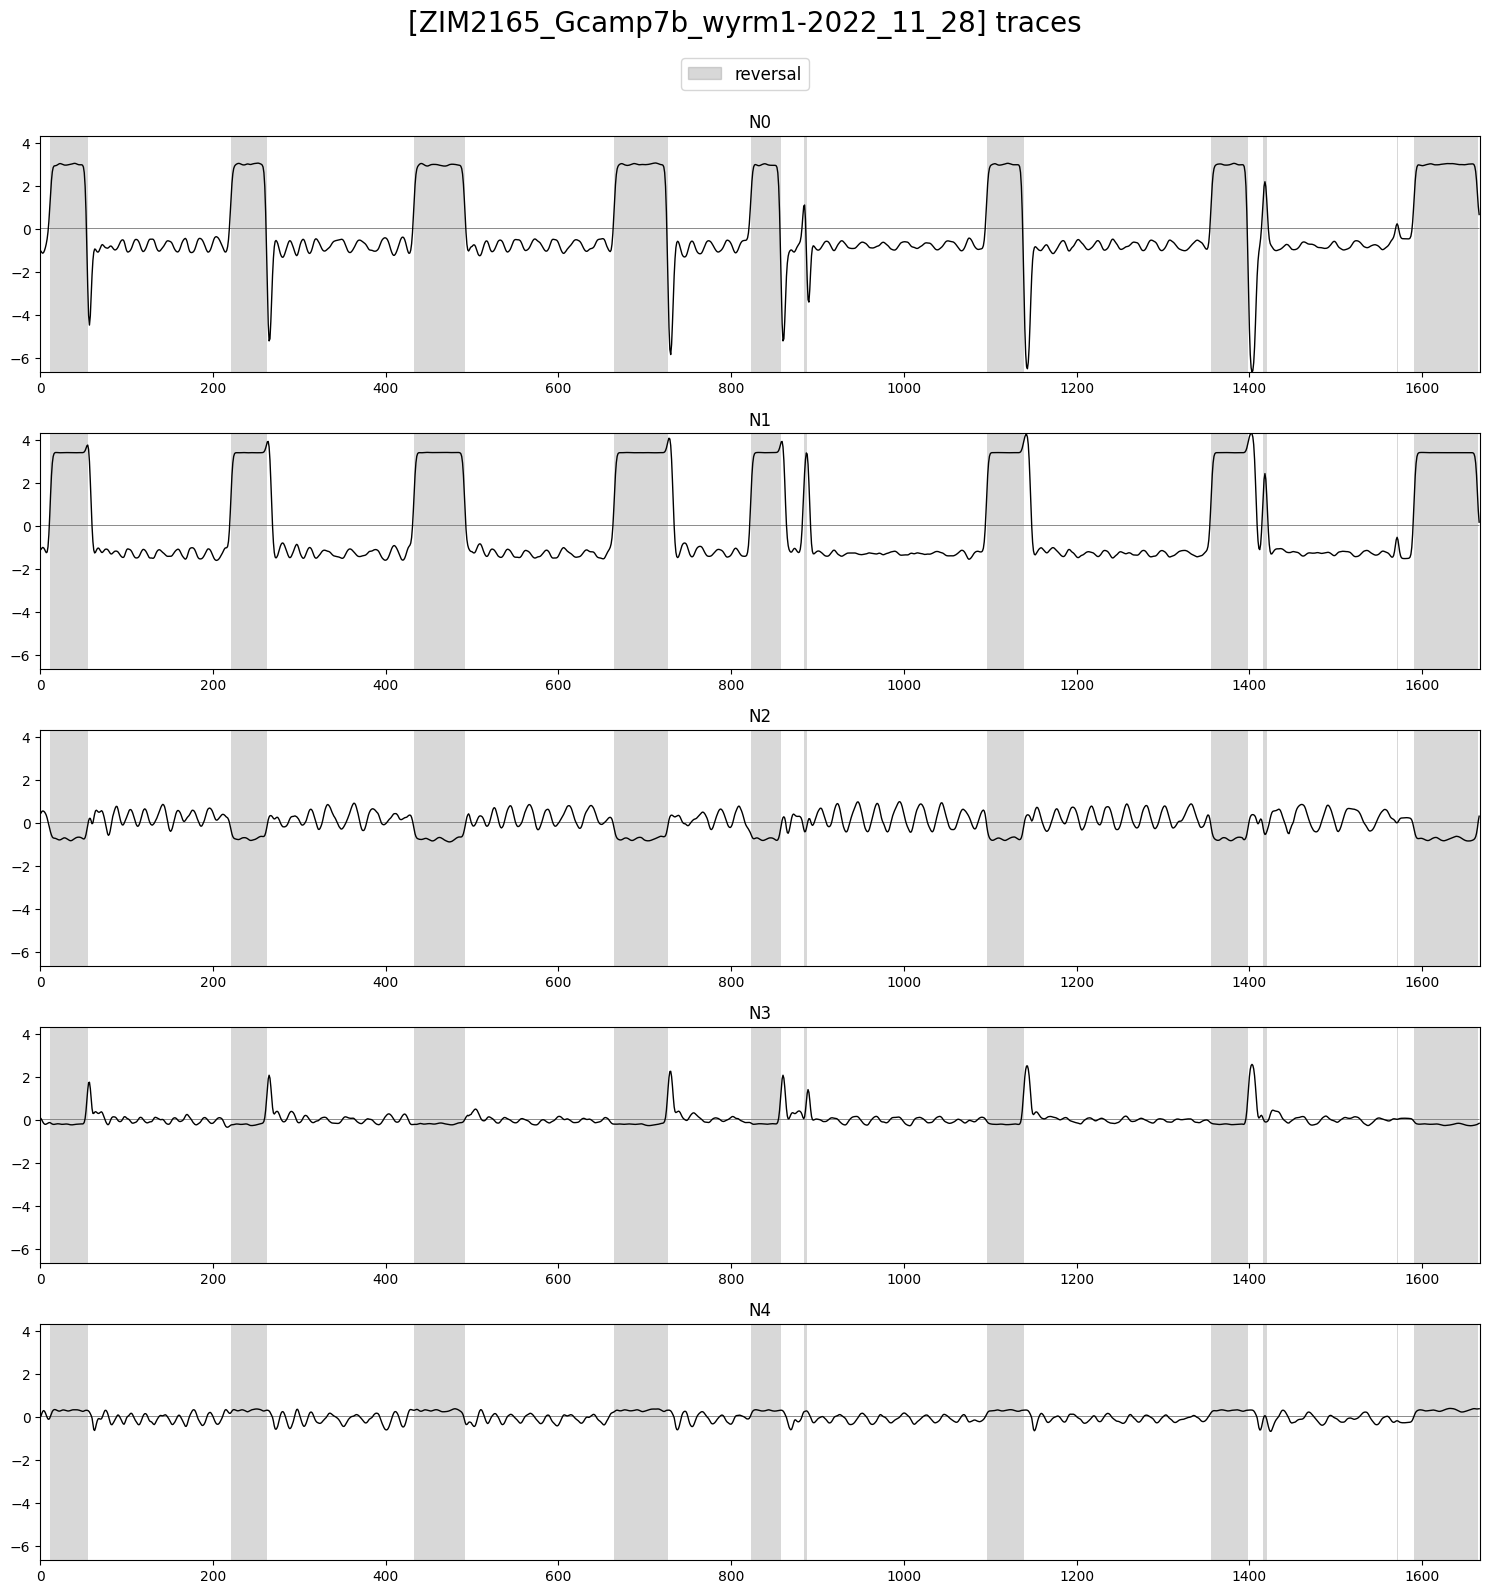

In [26]:
plot_utils.plot_traces(traces[neuron_labels],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces', ylimits=None)

# sklearn PCA

In [27]:
X = traces.values

In [28]:
# pca = PCA(n_components=dims)
# pca.fit(X)
# X_l_h = pca.transform(X)
# X_rec_h = pca.inverse_transform(X_l_h)

In [29]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca([traces], zscore=True,
												 n_pc=dims)

X_l_h_df = modes_manifold[0]
X_l_h = X_l_h_df.values
X_rec_h_df = recos_manifold[0]
X_rec_h = X_rec_h_df.values

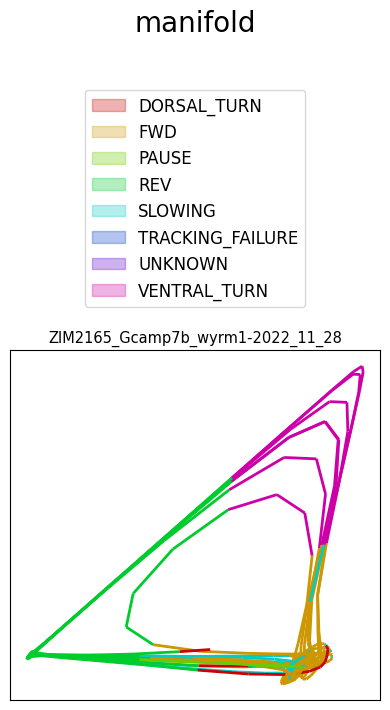

In [30]:
# X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'PC{i}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_h_df],
							  [discrete_states],
							  None, None,
							  title='manifold', top_space=3.5,
							  save_path=None)

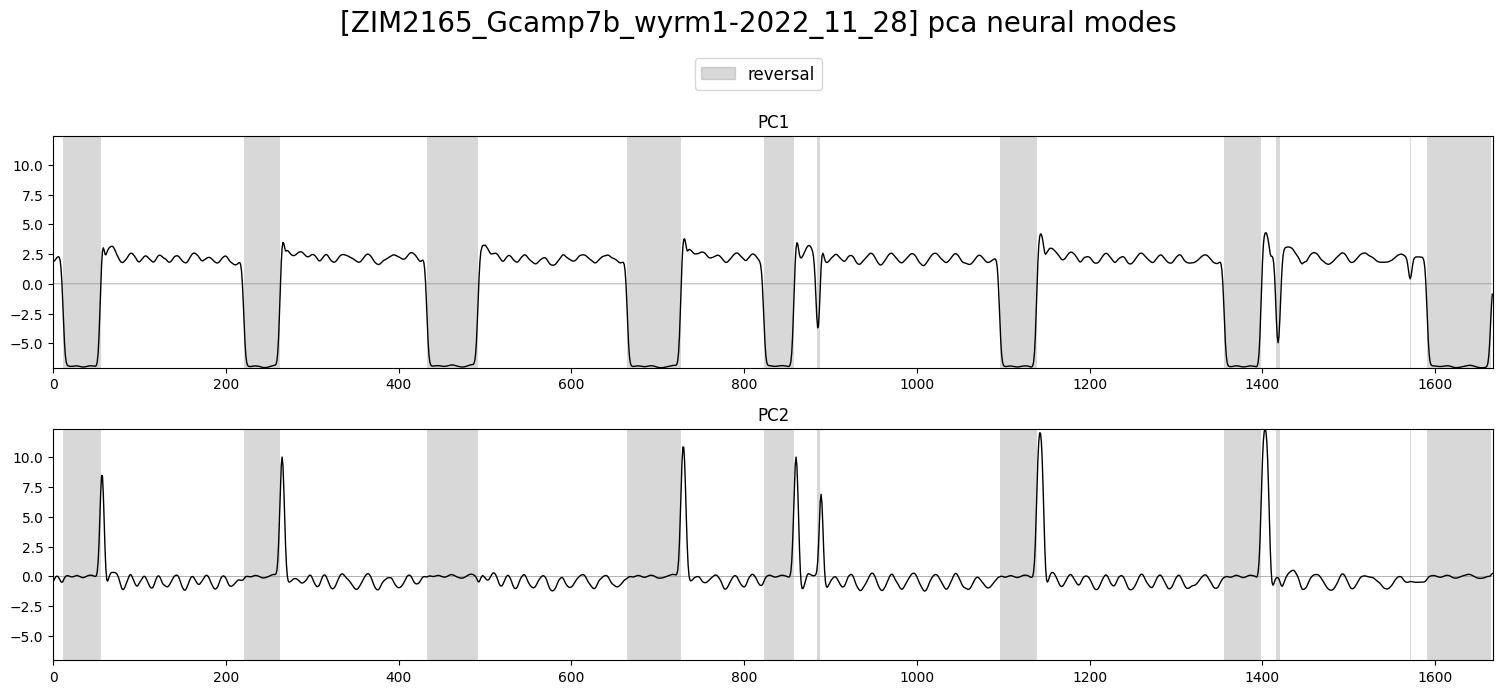

In [31]:
plot_utils.plot_traces([X_l_h_df],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca neural modes', ylimits=None)

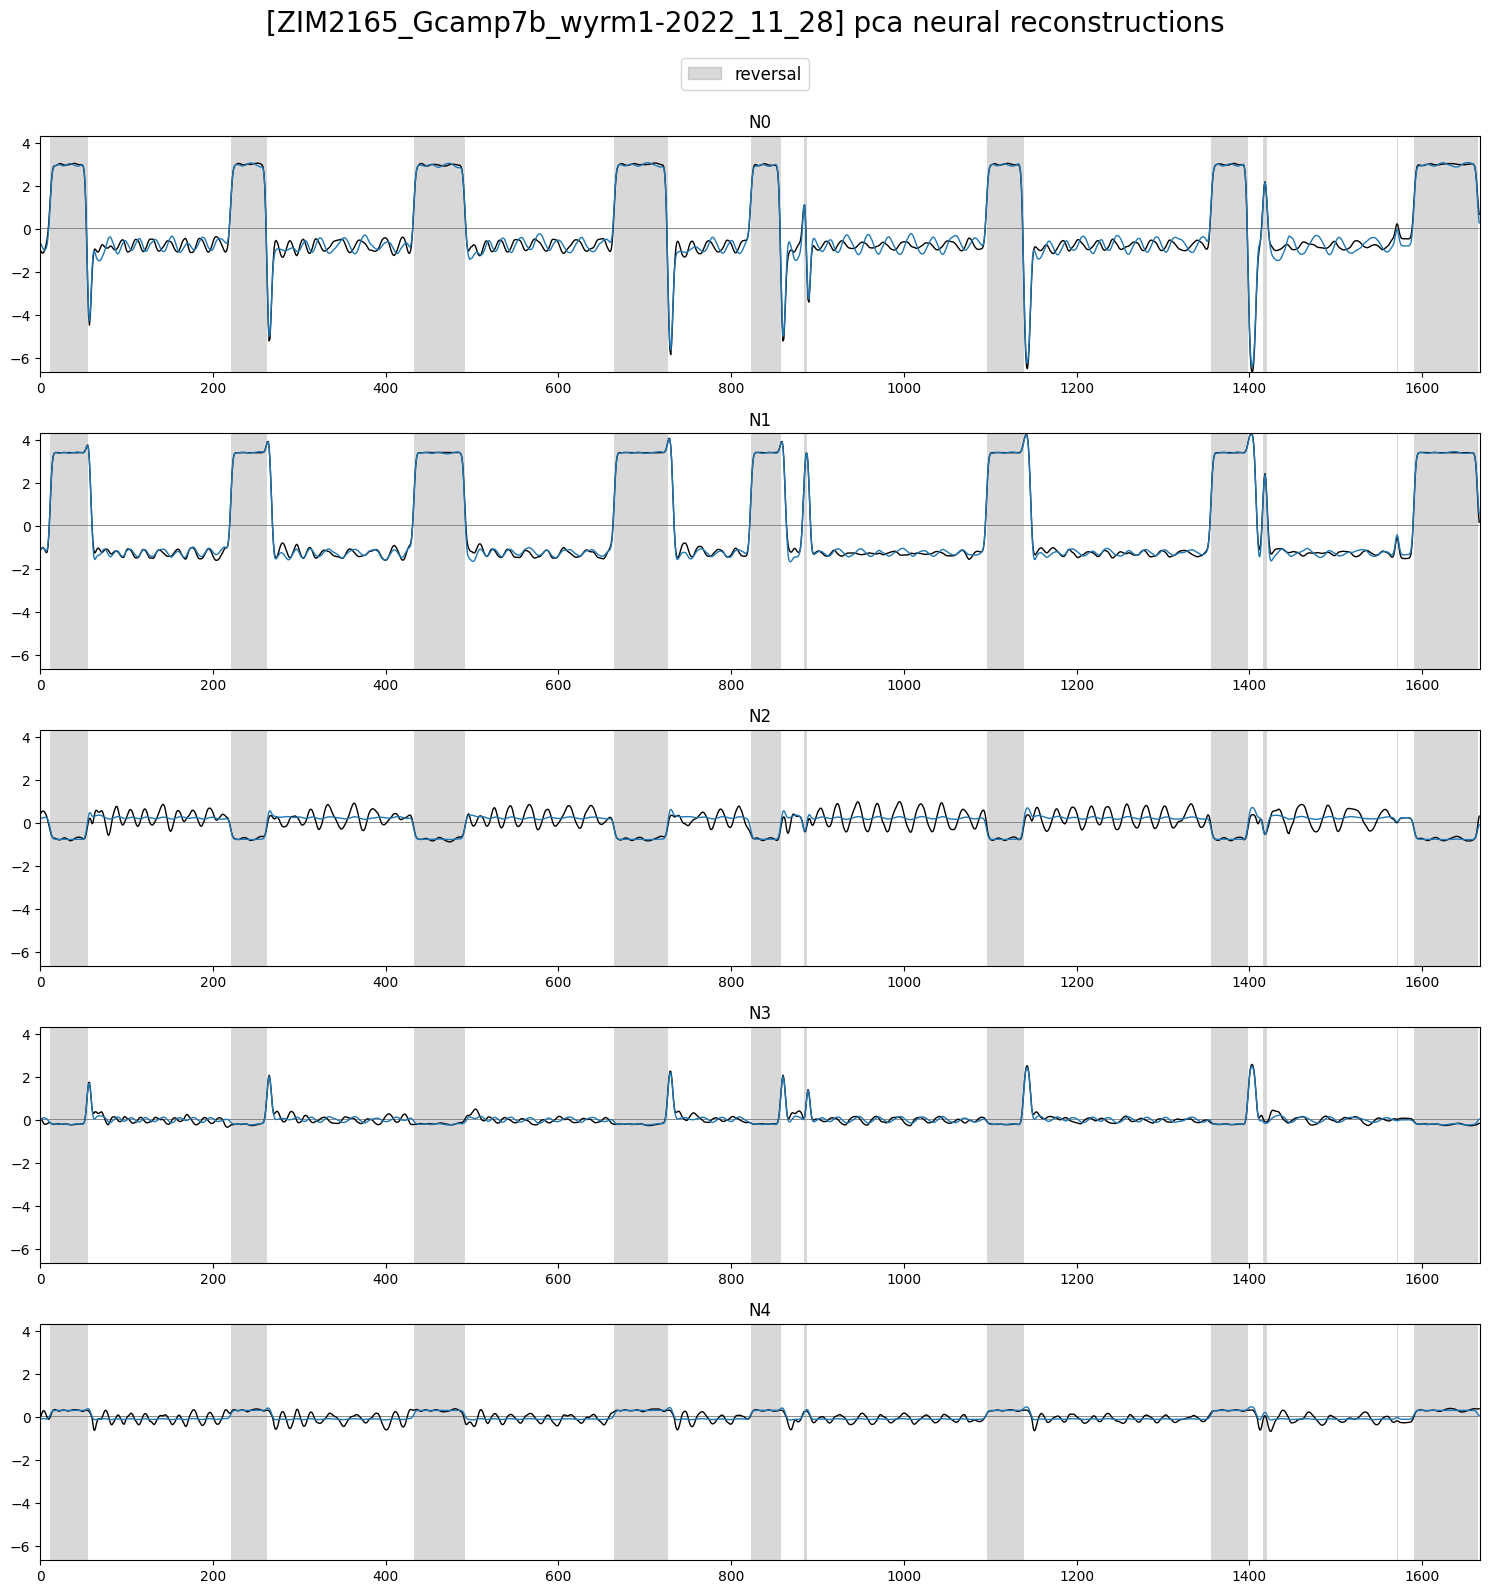

In [32]:
# X_rec_h_df = pd.DataFrame(data=X_rec_h, columns=traces.columns)

plot_utils.plot_traces([traces[neuron_labels], X_rec_h_df[neuron_labels]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca neural reconstructions', ylimits=None)

# soft PCA

In [33]:
def init_params(N, seeds, n_neurons, n_dimensions):
	return {
		'prep': {
			'N': {
				'mean': N.mean(axis=0),
				'std': jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std),
			},
			# 'N': {
			# 	'mean': np.zeros((n_neurons,)),
			# 	'std': np.ones((n_neurons,)),
			# },
		},
		'model': {
			'U': 1E-3 * jax.random.normal(seeds[0], (n_neurons, n_dimensions)),
		}
	}


# @jax.jit
# def orthogonalize_qr(A):
# 	Q, R = jnp.linalg.qr(A)
# 	return Q * jnp.diag(R)  # also fixes sign ambiguity for a deterministic mapping


@jax.jit
def orthonormalize_qr(A):
	Q, R = jnp.linalg.qr(A)
	signs = jnp.sign(jnp.diag(R))  # fix sign ambiguity for a deterministic mapping
	return Q * jnp.where(signs == 0, 1.0, signs)


@jax.jit
def get_reconstruction_matrix(X, Y, U):
	# reconstruct Y (target) using X (predictor)

	# return jnp.linalg.inv(X.T @ X) @ X.T @ Y
	#
	# XTX = X.T @ X
	# lam = 1E2 * jnp.finfo(XTX.dtype).eps * jnp.maximum(jnp.trace(XTX) / XTX.shape[0], 1.0)
	# return jnp.linalg.solve(XTX + lam * jnp.eye(X.shape[1], dtype=X.dtype), X.T @ Y)

	# return U.T
	# return jnp.linalg.pinv(U)
	return jnp.linalg.lstsq(X, Y)[0]



@jax.jit
def predict(params, N):
	prep_n = jax.lax.stop_gradient(params['prep']['N'])

	N_mean, N_std = prep_n['mean'], prep_n['std']

	U = params['model']['U']

	# UQ = U
	UQ = orthonormalize_qr(U)

	N_zs = (N - N_mean) / N_std

	N_man = N_zs @ UQ

	N_zs_rec = N_man @ get_reconstruction_matrix(N_man, N_zs, UQ)
	N_rec = N_zs_rec * N_std + N_mean

	return N_man, N_rec


def loss_fn(params, N):
	N_man, N_rec = predict(params, N)

	# man_loss = jnp.mean(jnp.mean(jnp.abs(N - N_rec) ** 1, axis=0))
	# man_loss = jnp.mean(jnp.mean(jnp.abs(N - N_rec) ** 1, axis=0))
	man_loss = jnp.mean(jnp.mean(jnp.abs(N - N_rec) ** 1, axis=0))
	# man_loss = jnp.mean((N - N_rec) ** 2)  # ^p?

	return man_loss

	# N_res = N - N_rec
	# N_res_pred = jnp.zeros(N_res.shape)
	# mpe_loss = jnp.mean(jnp.mean(jnp.abs(N_res_pred - N_res) ** 1, axis=0))

	# return mpe_loss

loss_and_grads = jax.jit(jax.value_and_grad(loss_fn, has_aux=False))


def update(opt_update, opt_state, params, N):
	loss, grads = loss_and_grads(params, N)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return opt_state, params_new, loss

update = jax.jit(update, static_argnums=(0,))

In [34]:
def train(N, hyperparams):
	max_epochs = hyperparams['max_epochs']
	n_dimensions = hyperparams['dimensions']
	learning_rate = hyperparams['learning_rate']

	n_neurons = N.shape[1]

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)

	params = init_params(N, seeds, n_neurons, n_dimensions)
	# optimizer = optax.adam(learning_rate)
	optimizer = optax.adam(
		learning_rate=optax.cosine_decay_schedule(
			init_value=learning_rate,
			decay_steps=max_epochs,
			alpha=1E-4
		)
	)
	optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
	opt_state = optimizer.init(params)

	losses_train = []
	for epoch in range(max_epochs):
		opt_state, params, loss_train = update(optimizer.update, opt_state, params, N)
		losses_train.append(loss_train)

	return params, losses_train

In [35]:
hyperparameters = {
	'max_epochs': 10000,
	'learning_rate': 1E-0,
	'dimensions': dims
}

# splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces.shape[0]),
# 															   discrete_states[['REV']].values))
#
# results = list()
# for i in range(len(splits)):
# X_train, X_test = X[splits[i][0]], X[splits[i][1]]
# params, losses_train = train(X_train, hyperparameters)
# X_l_s, X_rec_s = predict(params, X)
# results.append((X_l_s, X_rec_s, losses_train))

params, losses_train = train(X, hyperparameters)
X_l_s, X_rec_s = predict(params, X)

In [36]:
# plot_utils.plot_losses_splits([filename], [np.array([res[2] for res in results])],
# 							  n_plots=1)

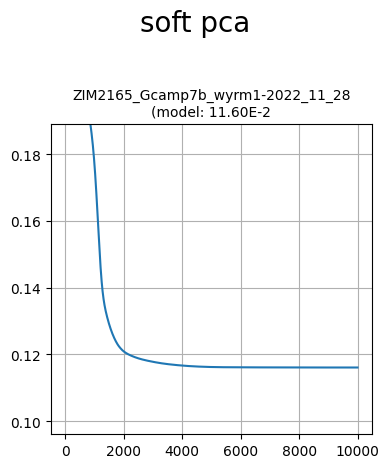

In [37]:
losses = np.array(losses_train)

plot_utils.plot_loss(filename,
					 losses,
					 title='soft pca', ylimits=0.2, plots_per_row=1)

In [38]:
# splits = 5
# plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
# 						  [pd.DataFrame(results[s][0], columns=[f'PC{i+1}' for i in range(dims)]) for s in range(splits)],
# 						  [discrete_states for s in range(splits)],
# 						  None, None,
# 						  title='manifold', plots_per_row=splits, top_space=3.5,
# 						  save_path=None)

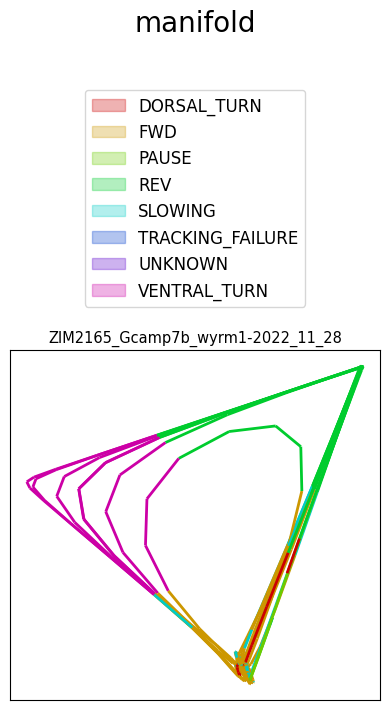

In [39]:
X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'PC{i+1}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_s_df],
							  [discrete_states],
							  None, None,
							  title='manifold', top_space=3.5,
							  save_path=None)

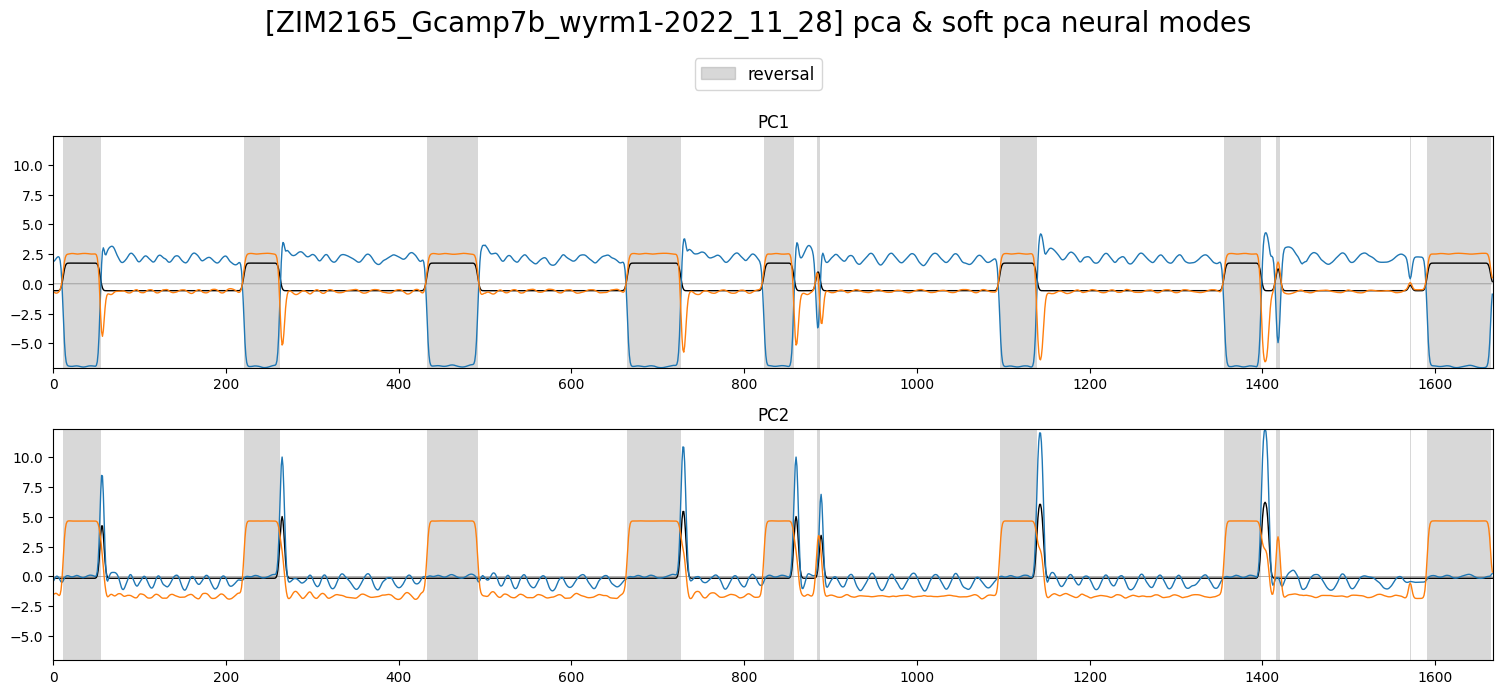

In [40]:
plot_utils.plot_traces([modes.set_axis([f'PC{i+1}' for i in range(dims)], axis=1),
						X_l_h_df,
						X_l_s_df],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca & soft pca neural modes', ylimits=None)

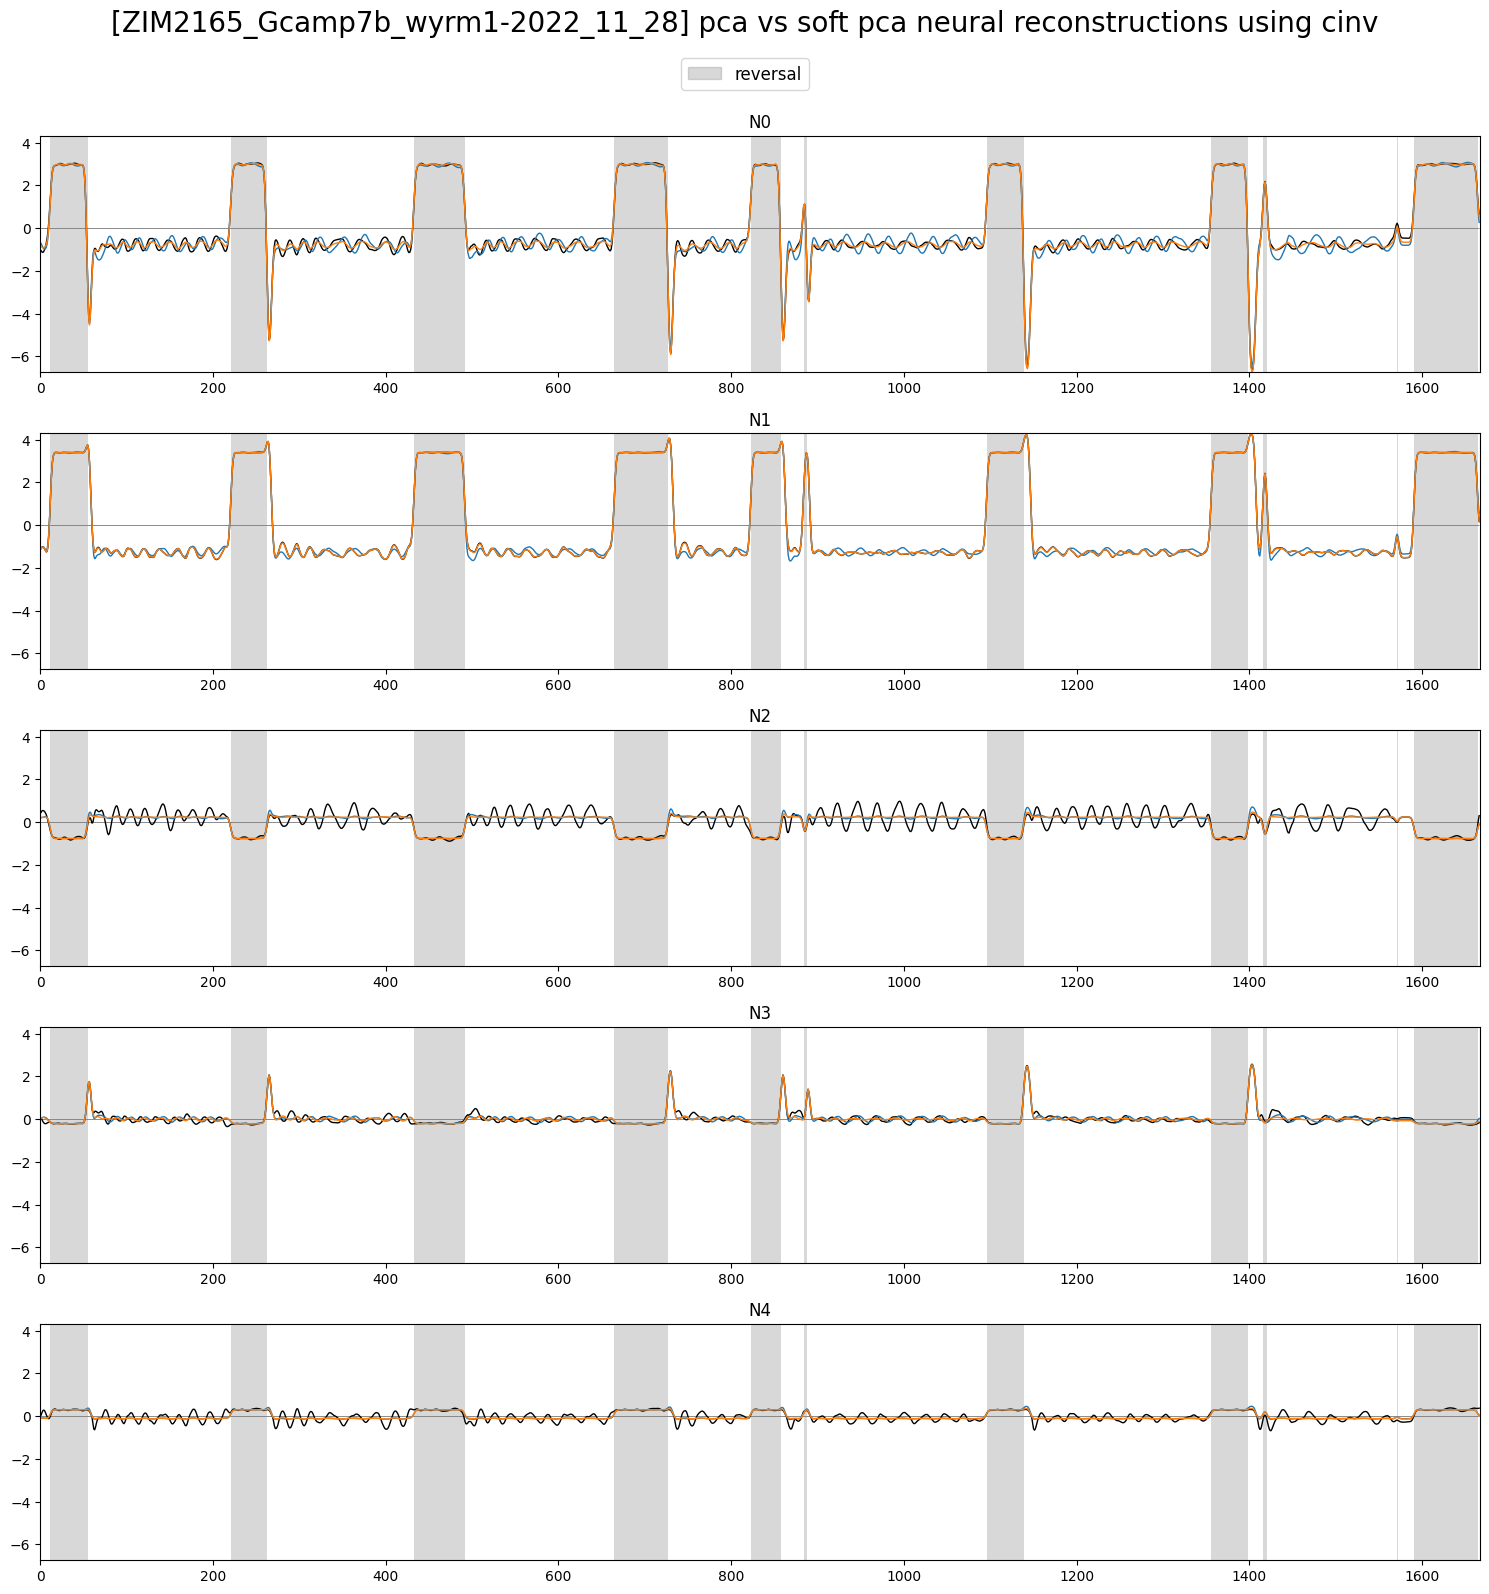

In [41]:
X_rec_s_df = pd.DataFrame(data=X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces[neuron_labels], X_rec_h_df[neuron_labels], X_rec_s_df[neuron_labels]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca vs soft pca neural reconstructions using cinv', ylimits=None)

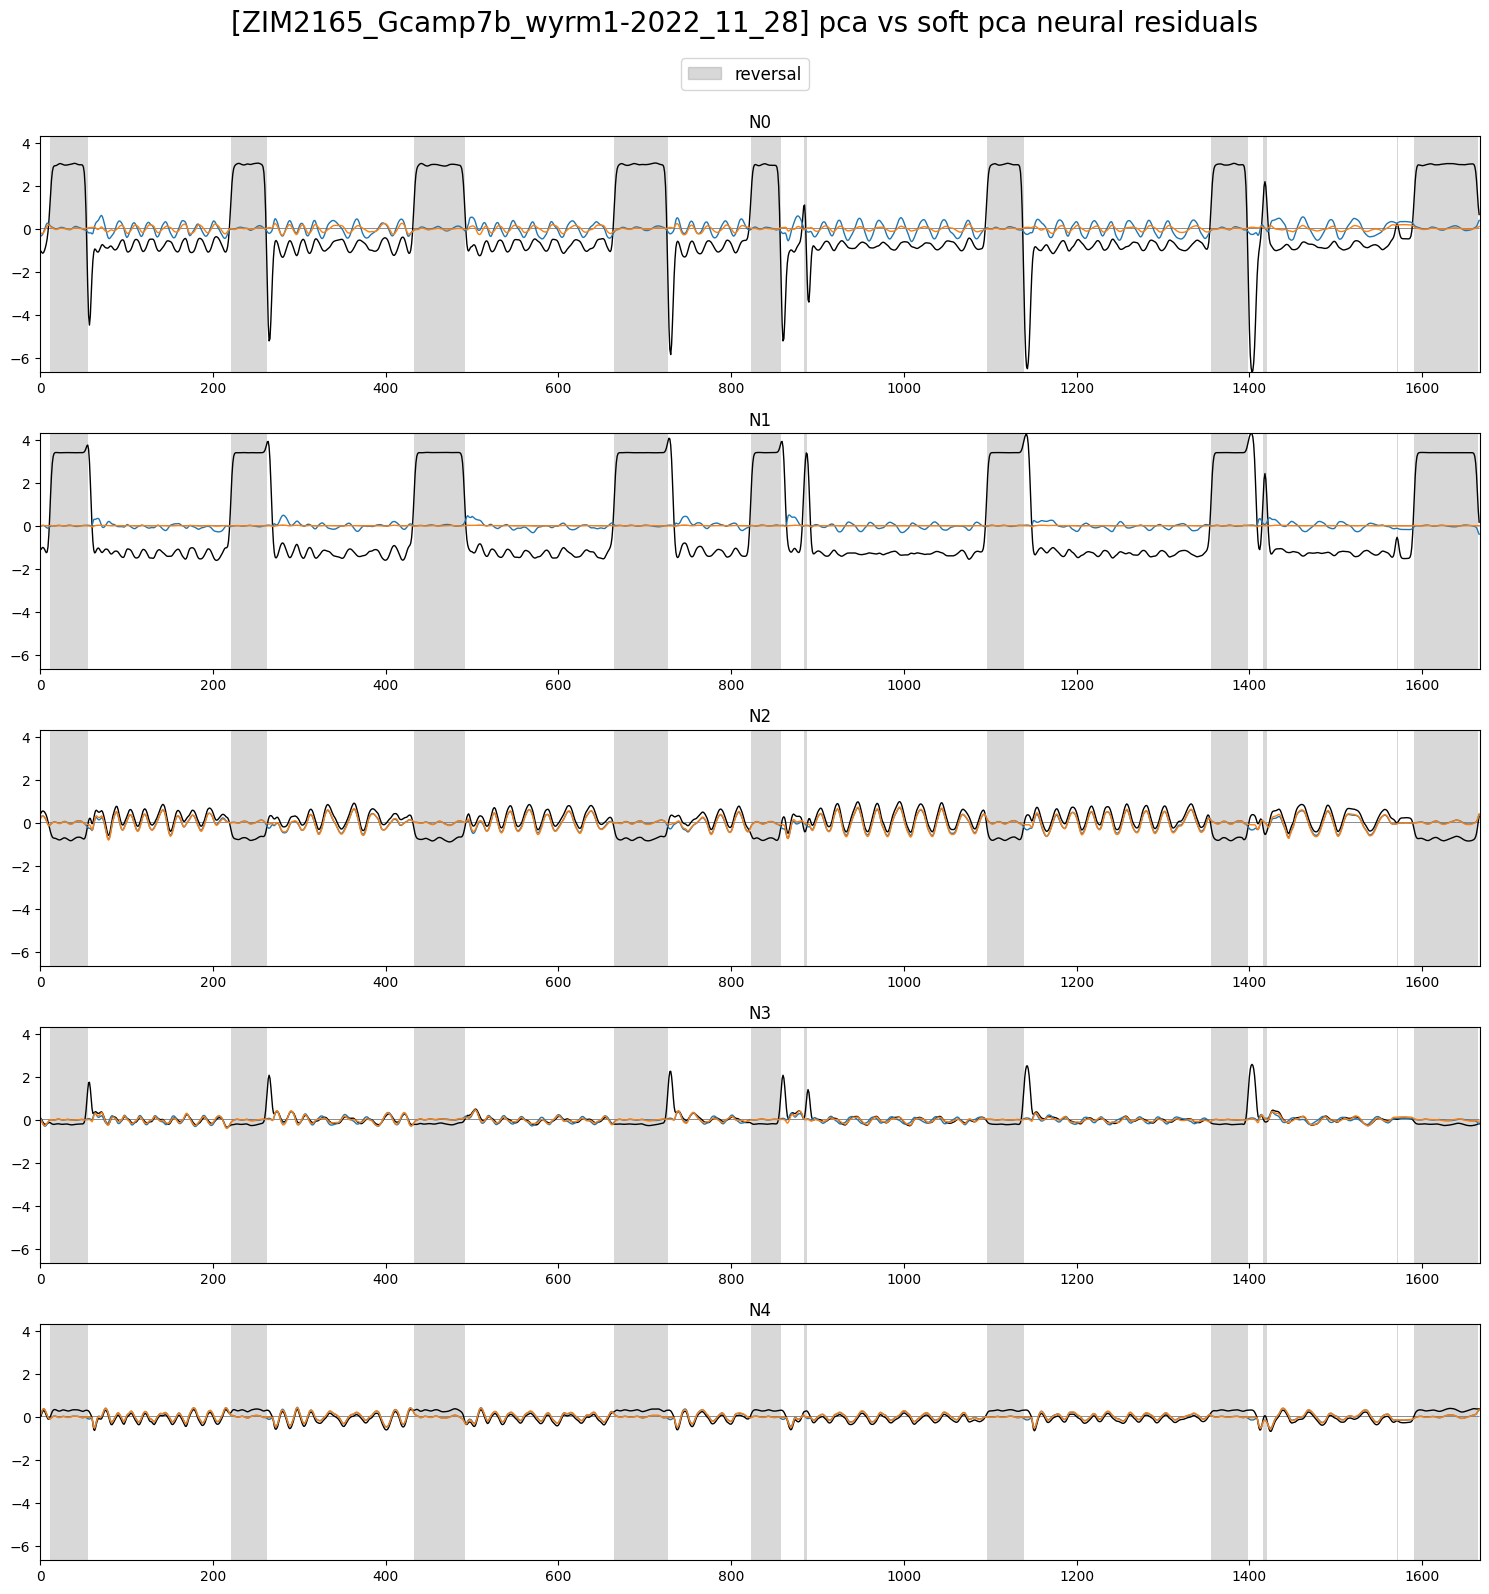

In [42]:
X_res_h_df = pd.DataFrame(data=X - X_rec_h, columns=traces.columns)
X_res_s_df = pd.DataFrame(data=X - X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces[neuron_labels], X_res_h_df[neuron_labels], X_res_s_df[neuron_labels]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca vs soft pca neural residuals', ylimits=None)

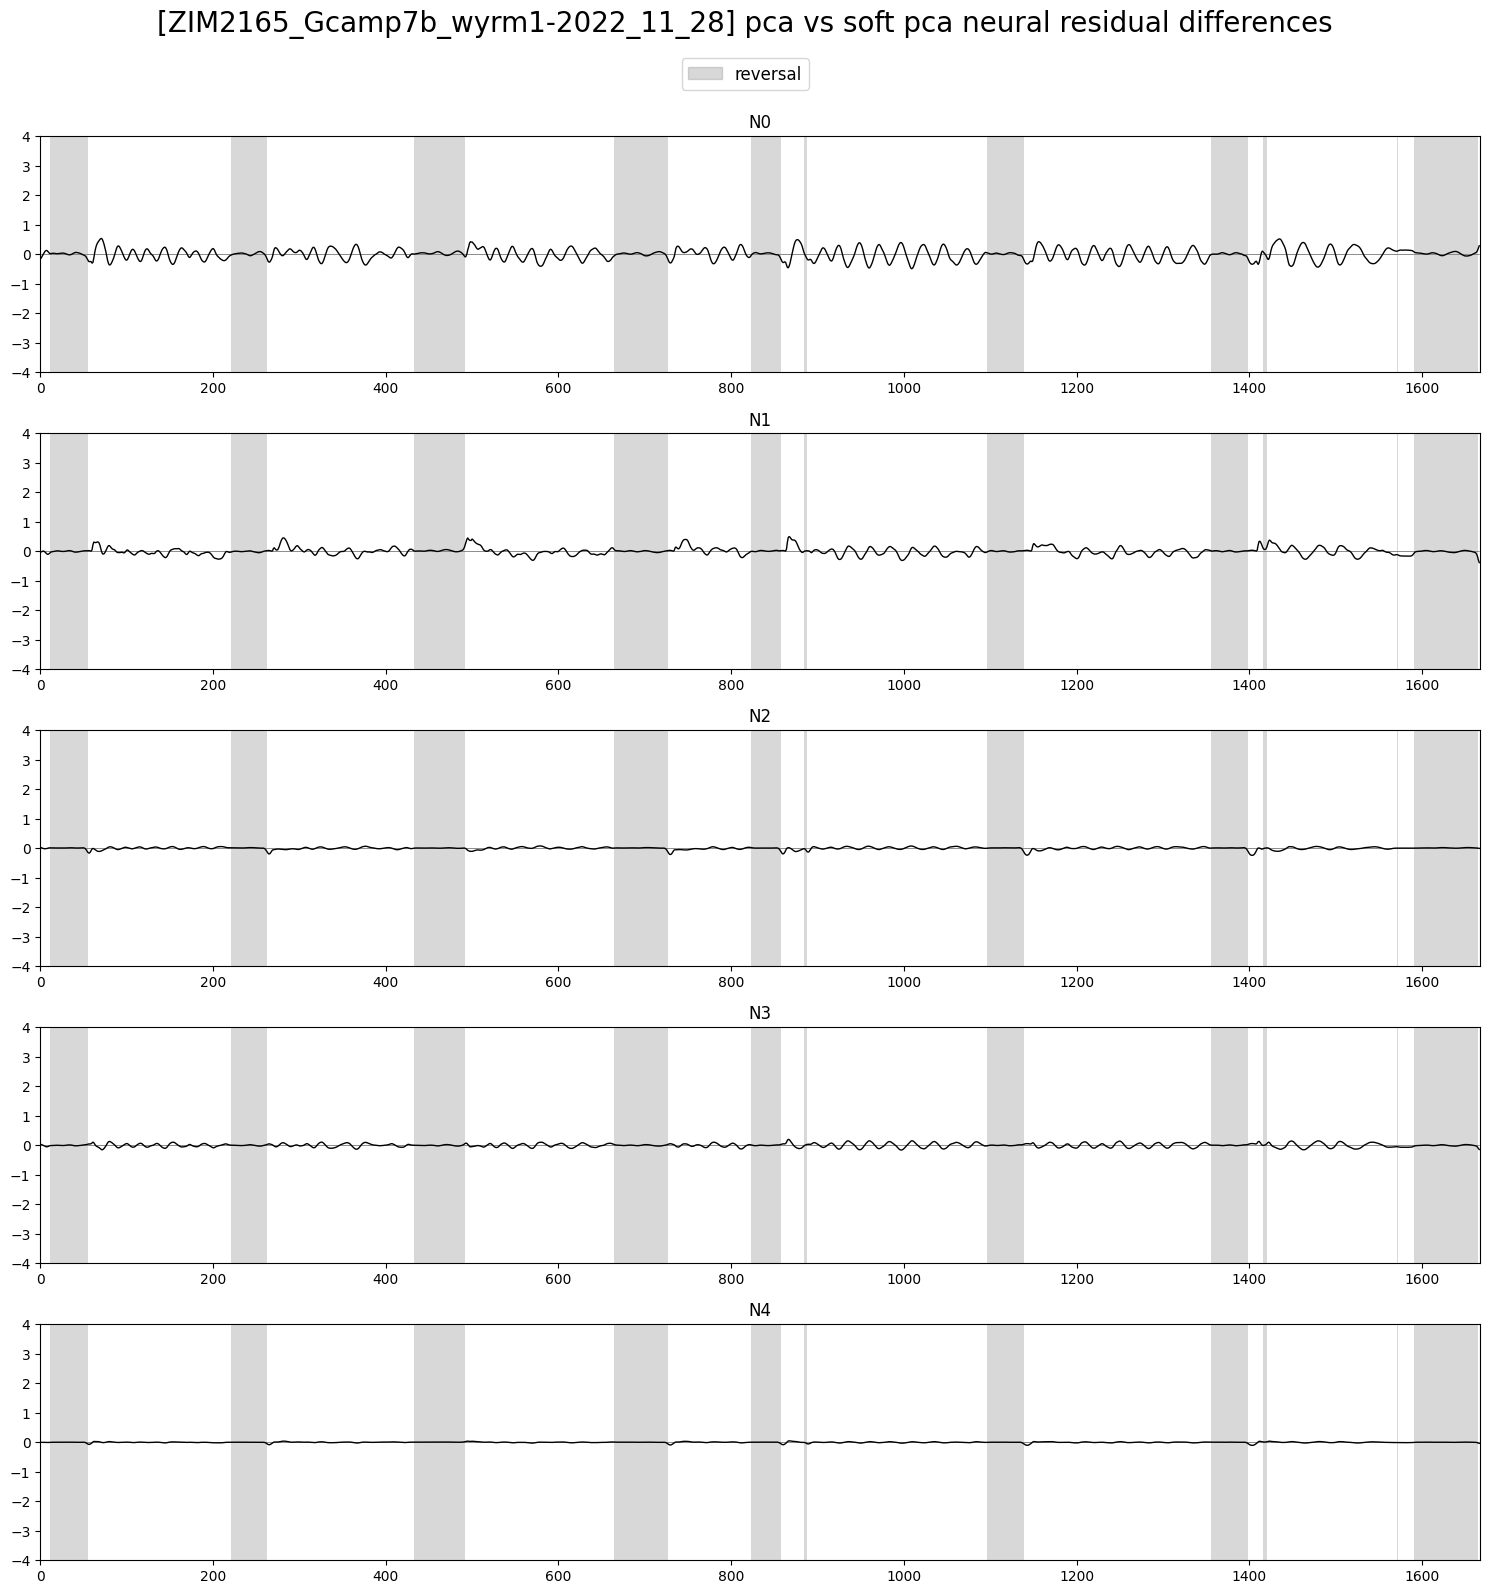

In [44]:
plot_utils.plot_traces([X_res_h_df[neuron_labels] - X_res_s_df[neuron_labels]],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] pca vs soft pca neural residual differences', ylimits=(-4, 4))